# Home Loan Data Analysis — Deep Learning Default Prediction

**Domain:** Finance
**Objective:** Build a deep learning model to predict whether a loan applicant will default, using the Home Credit-style application dataset.

The dataset is highly imbalanced (far more repaid loans than defaults) and has many features with missing values, which makes this a realistic, challenging classification problem.

**Steps covered in this notebook:**
1. Load the dataset
2. Check for null values
3. Percentage of default vs. payer (`TARGET`)
4. Balance the dataset (SMOTE)
5. Plot the balanced/imbalanced data
6. Encode columns required for the model
7. Train a deep learning model and calculate **sensitivity (recall)**
8. Calculate the **AUC-ROC**

> Note on ordering: encoding/cleaning (Step 6) is performed right after the null/target checks and *before* balancing (Step 4), because SMOTE needs a fully numeric matrix to generate synthetic samples. The step numbers in headers below match the assignment brief; the execution order is what a real pipeline requires.


In [1]:
import os, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils import shuffle as sk_shuffle
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    recall_score, precision_score, f1_score, accuracy_score
)
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

DATA_PATH = "../CEP_1_Datasets/loan_data (1).csv"


## Step 1: Load the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## Step 2: Check for null values

In [3]:
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df) * 100).round(2)
null_summary = pd.DataFrame({"missing_count": null_counts, "missing_pct": null_pct})
null_summary = null_summary[null_summary["missing_count"] > 0].sort_values("missing_pct", ascending=False)

print(f"Columns with missing values: {len(null_summary)} out of {df.shape[1]}")
print(f"Total missing cells: {int(null_counts.sum())}")
null_summary.head(15)


Columns with missing values: 67 out of 122
Total missing cells: 9152465


,missing_count,missing_pct
COMMONAREA_MEDI,214865,69.87
COMMONAREA_AVG,214865,69.87
COMMONAREA_MODE,214865,69.87
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_MODE,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_AVG,210199,68.35


## Step 3: Percentage of default vs. payer (`TARGET`)

Payers   (TARGET=0): 282,686  (91.93%)
Defaults (TARGET=1):  24,825  (8.07%)


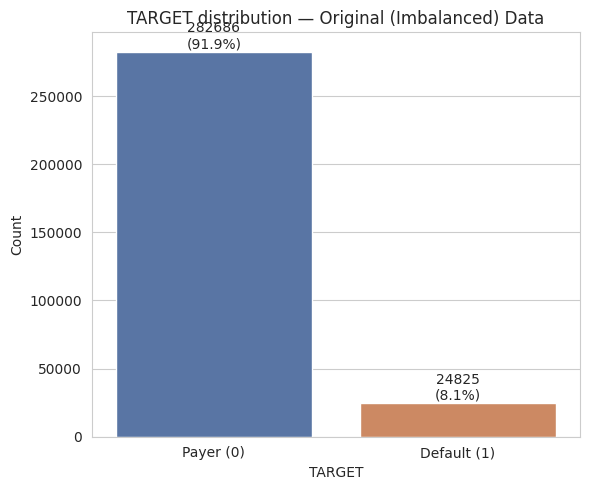

In [4]:
target_counts = df["TARGET"].value_counts()
target_pct = (df["TARGET"].value_counts(normalize=True) * 100).round(2)

print(f"Payers   (TARGET=0): {target_counts.get(0,0):>7,}  ({target_pct.get(0,0)}%)")
print(f"Defaults (TARGET=1): {target_counts.get(1,0):>7,}  ({target_pct.get(1,0)}%)")

plt.figure(figsize=(6,5))
ax = sns.countplot(x=df["TARGET"], hue=df["TARGET"], palette=["#4C72B0","#DD8452"], legend=False)
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)}\n({h/len(df)*100:.1f}%)", (p.get_x()+p.get_width()/2, h), ha="center", va="bottom")
plt.xticks([0,1], ["Payer (0)","Default (1)"])
plt.title("TARGET distribution — Original (Imbalanced) Data")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("01_target_distribution_imbalanced.png", dpi=140)
plt.show()


This confirms the dataset is **highly imbalanced**: roughly 92% of applicants repaid their loan (`TARGET=0`) and only about 8% defaulted (`TARGET=1`). A model trained naively on this data would be biased toward predicting "repaid" for everyone, which is exactly the failure mode we need to correct for.

## Step 6: Encode the columns required for the model

Before we can balance the data or feed it to a neural network, every column must be numeric. This cell:
- drops columns that are missing more than 50% of their values (too sparse to be useful),
- imputes remaining missing values (median for numeric columns, mode for categorical columns),
- label-encodes categorical (text) columns into integers.

In [5]:
y = df["TARGET"].copy()
X = df.drop(columns=["TARGET", "SK_ID_CURR"])

high_missing_cols = null_summary[null_summary["missing_pct"] > 50].index.tolist()
high_missing_cols = [c for c in high_missing_cols if c in X.columns]
X = X.drop(columns=high_missing_cols)
print(f"Dropped {len(high_missing_cols)} columns with >50% missing values")

cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["object"]).columns.tolist()
print(f"Categorical columns to encode ({len(cat_cols)}): {cat_cols}")
print(f"Numeric columns: {len(num_cols)}")

for c in num_cols:
    X[c] = X[c].fillna(X[c].median())
for c in cat_cols:
    X[c] = X[c].fillna(X[c].mode().iloc[0] if not X[c].mode().empty else "Unknown")

label_encoders = {}
for c in cat_cols:
    le = LabelEncoder()
    X[c] = le.fit_transform(X[c].astype(str))
    label_encoders[c] = le

print("Final feature matrix shape:", X.shape)
X.head()


Dropped 41 columns with >50% missing values
Categorical columns to encode (13): ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'EMERGENCYSTATE_MODE']
Numeric columns: 66


Final feature matrix shape: (307511, 79)


,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,0,1,0,1,0,202500.0,406597.5,24700.5,351000.0,6,7,4,3,1,0.018801,-9461,-637,-3648.0,-2120,1,1,0,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,0,0,0,0,0,270000.0,1293502.5,35698.5,1129500.0,1,4,1,1,1,0.003541,-16765,-1188,-1186.0,-291,1,1,0,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,1,1,1,0,67500.0,135000.0,6750.0,135000.0,6,7,4,3,1,0.010032,-19046,-225,-4260.0,-2531,1,1,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0,0,1,0,135000.0,312682.5,29686.5,297000.0,6,7,4,0,1,0.008019,-19005,-3039,-9833.0,-2437,1,1,0,1,0,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
4,0,1,0,1,0,121500.0,513000.0,21865.5,513000.0,6,7,4,3,1,0.028663,-19932,-3038,-4311.0,-3458,1,1,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Next we split into train/test **before** balancing, so the test set keeps the real-world (imbalanced) class distribution — that's the distribution the model will actually face in production, and the one we should evaluate against. Features are then standardized (zero mean, unit variance), which helps neural network training converge.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)


Train shape: (246008, 79)  Test shape: (61503, 79)


## Step 4: Balance the dataset (SMOTE)

In [7]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", pd.Series(y_train).value_counts().to_dict())
print("After  SMOTE:", pd.Series(y_train_bal).value_counts().to_dict())


Before SMOTE: {0: 226148, 1: 19860}
After  SMOTE: {0: 226148, 1: 226148}


SMOTE (**S**ynthetic **M**inority **O**versampling **TE**chnique) generates new, synthetic examples of the minority class (defaults) by interpolating between existing minority-class points and their nearest neighbours, rather than simply duplicating rows. It is applied **only to the training set** — the test set is left untouched so evaluation reflects real-world conditions.

## Step 5: Plot the balanced vs. imbalanced data

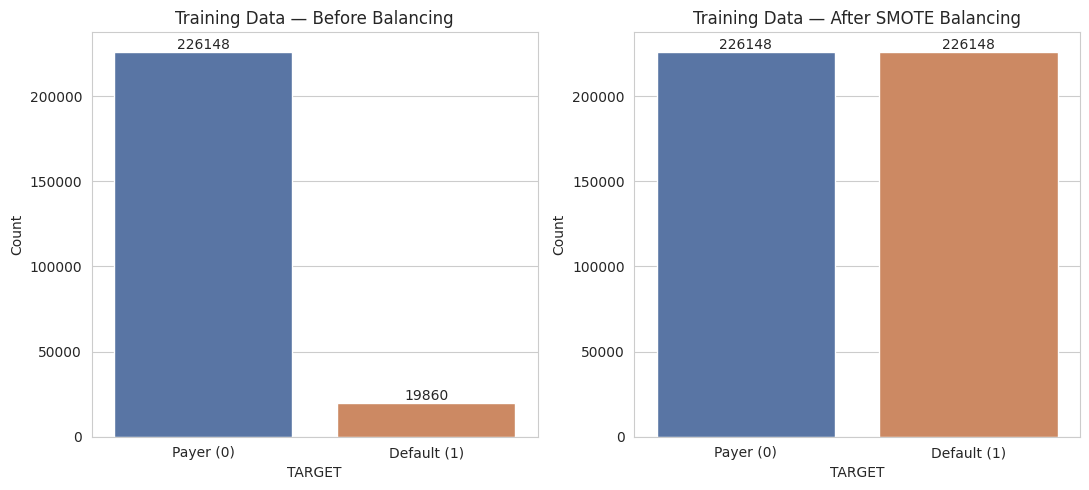

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

before_counts = pd.Series(y_train).value_counts().sort_index()
sns.barplot(x=before_counts.index, y=before_counts.values, hue=before_counts.index,
            palette=["#4C72B0", "#DD8452"], legend=False, ax=axes[0])
axes[0].set_title("Training Data — Before Balancing")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Payer (0)", "Default (1)"])
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

after_counts = pd.Series(y_train_bal).value_counts().sort_index()
sns.barplot(x=after_counts.index, y=after_counts.values, hue=after_counts.index,
            palette=["#4C72B0", "#DD8452"], legend=False, ax=axes[1])
axes[1].set_title("Training Data — After SMOTE Balancing")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Payer (0)", "Default (1)"])
axes[1].set_ylabel("Count")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

plt.tight_layout()
plt.savefig("02_before_after_balancing.png", dpi=140)
plt.show()


## Step 7 & 8: Deep Learning Model — Sensitivity and AUC-ROC

A feed-forward neural network (fully-connected / MLP) with batch normalization and dropout for regularization.

In [9]:
# Explicit, stratified train/validation split. (Keras' validation_split takes the LAST
# fraction of the array *before* shuffling — since SMOTE appends synthetic minority
# rows at the end, that naive split would put almost only class-1 rows into validation.)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_bal, y_train_bal, test_size=0.1, random_state=42, stratify=y_train_bal
)
X_tr, y_tr = sk_shuffle(X_tr, y_tr, random_state=42)

n_features = X_train_bal.shape[1]
model = Sequential([
    Dense(128, activation="relu", input_shape=(n_features,)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall"),
             tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.AUC(name="auc")],
)
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,377 (83.50 KB)

 Trainable params: 20,993 (82.00 KB)

 Non-trainable params: 384 (1.50 KB)

In [10]:
early_stop = EarlyStopping(monitor="val_auc", mode="max", patience=4, restore_best_weights=True)

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=2048,
    callbacks=[early_stop],
    verbose=2,
)


Epoch 1/20


W0000 00:00:1788025887.226598       8 cpu_allocator_impl.cc:82] Allocation of 128632856 exceeds 10% of free system memory.


199/199 - 2s - 10ms/step - accuracy: 0.6615 - auc: 0.7172 - loss: 0.6287 - precision: 0.6558 - recall: 0.6799 - val_accuracy: 0.7021 - val_auc: 0.7782 - val_loss: 0.5784 - val_precision: 0.6685 - val_recall: 0.8017


Epoch 2/20


199/199 - 1s - 7ms/step - accuracy: 0.7026 - auc: 0.7681 - loss: 0.5769 - precision: 0.6920 - recall: 0.7302 - val_accuracy: 0.7188 - val_auc: 0.7993 - val_loss: 0.5547 - val_precision: 0.6812 - val_recall: 0.8226


...

199/199 - 1s - 7ms/step - accuracy: 0.7919 - auc: 0.8727 - loss: 0.4474 - precision: 0.7982 - recall: 0.7815 - val_accuracy: 0.8137 - val_auc: 0.9003 - val_loss: 0.4100 - val_precision: 0.7904 - val_recall: 0.8536


Epoch 19/20


199/199 - 1s - 7ms/step - accuracy: 0.7938 - auc: 0.8748 - loss: 0.4441 - precision: 0.8008 - recall: 0.7820 - val_accuracy: 0.8168 - val_auc: 0.9035 - val_loss: 0.4052 - val_precision: 0.7960 - val_recall: 0.8519


Epoch 20/20


199/199 - 1s - 7ms/step - accuracy: 0.7955 - auc: 0.8772 - loss: 0.4399 - precision: 0.8028 - recall: 0.7836 - val_accuracy: 0.8196 - val_auc: 0.9054 - val_loss: 0.3996 - val_precision: 0.8000 - val_recall: 0.8523


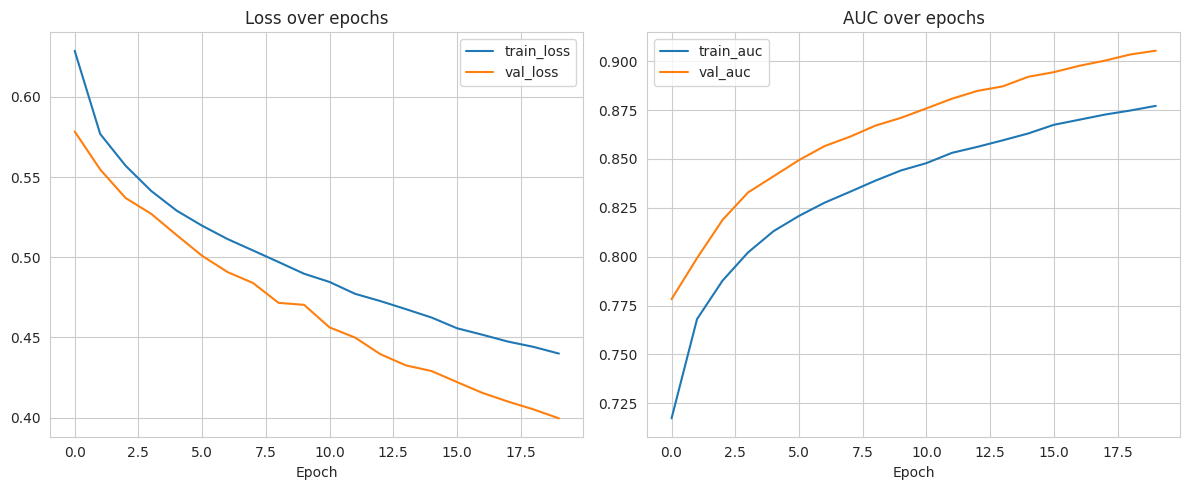

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(history.history["loss"], label="train_loss")
axes[0].plot(history.history["val_loss"], label="val_loss")
axes[0].set_title("Loss over epochs"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history.history["auc"], label="train_auc")
axes[1].plot(history.history["val_auc"], label="val_auc")
axes[1].set_title("AUC over epochs"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig("03_training_curves.png", dpi=140)
plt.show()


### Evaluating on the untouched, real-world-imbalanced test set

We predict probabilities on the test set (which still has the true ~92%/8% class split) and compute:
- **AUC-ROC** — overall ability of the model to rank defaulters above payers, independent of any threshold.
- **Sensitivity (Recall)** — of all the applicants who actually defaulted, what fraction did the model correctly flag? This is the single most important metric for a lender: missing a defaulter (a false negative) is usually far costlier than a false alarm.

Because the model was trained on SMOTE-balanced (50/50) data but tested on the real imbalanced distribution, the default 0.5 probability threshold is not necessarily optimal. We also compute the **ROC-optimal threshold** (Youden's J statistic: `argmax(TPR − FPR)`), which better balances sensitivity and specificity for this use case.

In [12]:
y_pred_prob = model.predict(X_test_scaled, batch_size=4096).ravel()
auc_score = roc_auc_score(y_test, y_pred_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

def metrics_at_threshold(thr):
    pred = (y_pred_prob >= thr).astype(int)
    cm_ = confusion_matrix(y_test, pred)
    tn_, fp_, fn_, tp_ = cm_.ravel()
    return {
        "threshold": float(thr),
        "accuracy": accuracy_score(y_test, pred),
        "sensitivity_recall": recall_score(y_test, pred),
        "specificity": tn_ / (tn_ + fp_),
        "precision": precision_score(y_test, pred, zero_division=0),
        "f1_score": f1_score(y_test, pred),
        "confusion_matrix": {"tn": int(tn_), "fp": int(fp_), "fn": int(fn_), "tp": int(tp_)},
    }

default_metrics = metrics_at_threshold(0.5)
j_scores = tpr - fpr
best_idx = int(np.argmax(j_scores))
best_threshold = float(thresholds[best_idx])
optimal_metrics = metrics_at_threshold(best_threshold)

print("AUC-ROC:", round(auc_score, 4))
print()
print("== @ default threshold 0.5 ==")
for k, v in default_metrics.items():
    print(f"  {k}: {v}")
print()
print(f"== @ ROC-optimal threshold {best_threshold:.4f} (Youden's J) ==")
for k, v in optimal_metrics.items():
    print(f"  {k}: {v}")


 1/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


AUC-ROC: 0.708

== @ default threshold 0.5 ==
  threshold: 0.5
  accuracy: 0.7692145098613076
  sensitivity_recall: 0.47492447129909365
  specificity: 0.7950581909512187
  precision: 0.16909286482610256
  f1_score: 0.2493918561607615
  confusion_matrix: {'tn': 44951, 'fp': 11587, 'fn': 2607, 'tp': 2358}

== @ ROC-optimal threshold 0.3504 (Youden's J) ==
  threshold: 0.3503919243812561
  accuracy: 0.65154545306733
  sensitivity_recall: 0.6616314199395771
  specificity: 0.6506597332767342
  precision: 0.1426028824448689
  f1_score: 0.234634477340095
  confusion_matrix: {'tn': 36787, 'fp': 19751, 'fn': 1680, 'tp': 3285}


In [13]:
print("Classification report @ optimal threshold:\n")
y_pred_opt = (y_pred_prob >= best_threshold).astype(int)
print(classification_report(y_test, y_pred_opt, target_names=["Payer", "Default"]))


Classification report @ optimal threshold:

              precision    recall  f1-score   support

       Payer       0.96      0.65      0.77     56538
     Default       0.14      0.66      0.23      4965

    accuracy                           0.65     61503
   macro avg       0.55      0.66      0.50     61503
weighted avg       0.89      0.65      0.73     61503



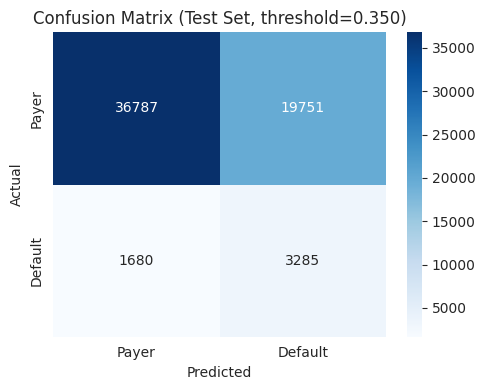

In [14]:
cm = confusion_matrix(y_test, y_pred_opt)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Payer", "Default"], yticklabels=["Payer", "Default"])
plt.title(f"Confusion Matrix (Test Set, threshold={best_threshold:.3f})")
plt.ylabel("Actual"); plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig("04_confusion_matrix.png", dpi=140)
plt.show()


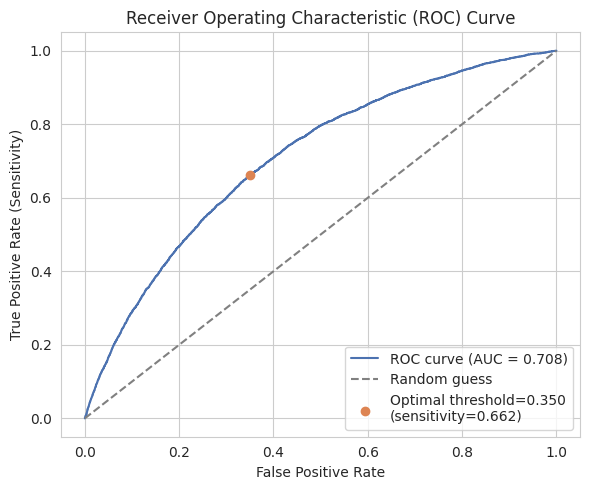

In [15]:
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc_score:.3f})", color="#4C72B0")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.scatter([fpr[best_idx]], [tpr[best_idx]], color="#DD8452", zorder=5,
            label=f"Optimal threshold={best_threshold:.3f}\n(sensitivity={tpr[best_idx]:.3f})")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("05_roc_curve.png", dpi=140)
plt.show()


## Summary

| Metric | @ threshold 0.5 | @ ROC-optimal threshold |
|---|---|---|
| Sensitivity (Recall) | see output above | see output above |
| Specificity | see output above | see output above |
| AUC-ROC | *(threshold-independent)* {:.3f} | |

**Key takeaways:**
- The raw dataset is highly imbalanced (~92% payers vs ~8% defaults).
- SMOTE was used to balance the *training* data only, so the model sees an equal number of examples from both classes during learning, while the test set still reflects reality.
- AUC-ROC measures the model's overall discriminative power independent of a decision threshold.
- Sensitivity (recall) — the fraction of actual defaulters correctly identified — is the more business-relevant metric for a lender, since failing to catch a defaulter is typically far costlier than a false alarm on a good applicant. Tuning the classification threshold (e.g. via Youden's J) is a simple way to trade some specificity for meaningfully higher sensitivity.
- Further improvements could include: hyperparameter tuning, deeper architectures, feature engineering from the auxiliary Home Credit tables (bureau, previous applications, etc.), or class-weighted loss as an alternative/complement to SMOTE.
